In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
import re

In [2]:
from platform import python_version
import sys
print(sys.executable)
print(python_version())

/dccstor/kcsys/brenow/repos/grokking-git/.venv/bin/python
3.10.14


In [3]:
def plot_accuracy(data, img_path = None, yaxis = (0.5, 1.0), alpha=1.0, fraction_list:list=None, num_samples_list:list=None):
    if fraction_list:
        data = data[data['fraction'].isin(fraction_list)]
    if num_samples_list:
        data = data[data['num_samples'].isin(num_samples_list)]
        
    # Set up the FacetGrid
    g = sns.FacetGrid(data, row='fraction', col='num_samples', margin_titles=True)
    
    # Map the plotting function to each subset of the data with alpha values
    g.map(sns.lineplot, 'step', 'test_accuracy', color='blue', alpha=alpha, label='Test Accuracy')
    g.map(sns.lineplot, 'step', 'train_accuracy', color='orange', alpha=alpha, label='Train Accuracy')

    if yaxis is not None:
        # Set the y-axis limits for all subplots
        g.set(ylim=yaxis)
    
    # Add legend
    handles, labels = g.axes[0, 0].get_legend_handles_labels()  # Get legend from any axis
    lgd = g.fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=2)
    
    # Adjust layout
    plt.tight_layout()
    fig = plt.gcf()
    if(img_path is not None):
        fig.savefig(img_path, bbox_extra_artists=(lgd,), bbox_inches='tight')
    plt.show()
    return fig

In [4]:
def get_all_csv(root_folder = 'experiments', verbose=False, recursive=False):

    # Loop through all folders in the root folder
    dataframes = []
    folder_list = [os.path.join(root_folder, folder) for folder in os.listdir(root_folder)]
    folder_list = [candidate for candidate in folder_list if os.path.isdir(candidate)]

    while len(folder_list):
        entry = folder_list.pop()
    
        if os.path.isdir(entry):
            # Check if the folder contains CSV files
            csv_files = [f for f in os.listdir(entry) if f.endswith('.csv')]
            if(verbose): print(csv_files)
            match = re.search( r".*frac\[(\d+(?:\.\d+)?)\].*", entry)
            
            if match:
                frac = float(match.group(1))
                # Loop through each CSV file in the folder
                for csv_file in csv_files:
                    # Read the CSV file into a pandas dataframe
                    dataframe = pd.read_csv(os.path.join(entry, csv_file))
                    dataframe["fraction"] = frac
                    dataframes.append(dataframe)
                if(verbose):
                    print(f"Folder {entry}, frac{frac}: has {len(csv_files)} csv files")
            else:
                candidates = [os.path.join(entry, folder) for folder in os.listdir(entry)]
                candidates = [candidate for candidate in candidates if os.path.isdir(candidate)]
                folder_list.extend(candidates)
                if(verbose):
                    print(f"No fraction value in folder {entry}")
    return pd.concat(dataframes) if len(dataframes) > 0 else None

Processing: ./experiments/exp_synthetic_equivariant
Ploting: ./experiments/exp_synthetic_equivariant


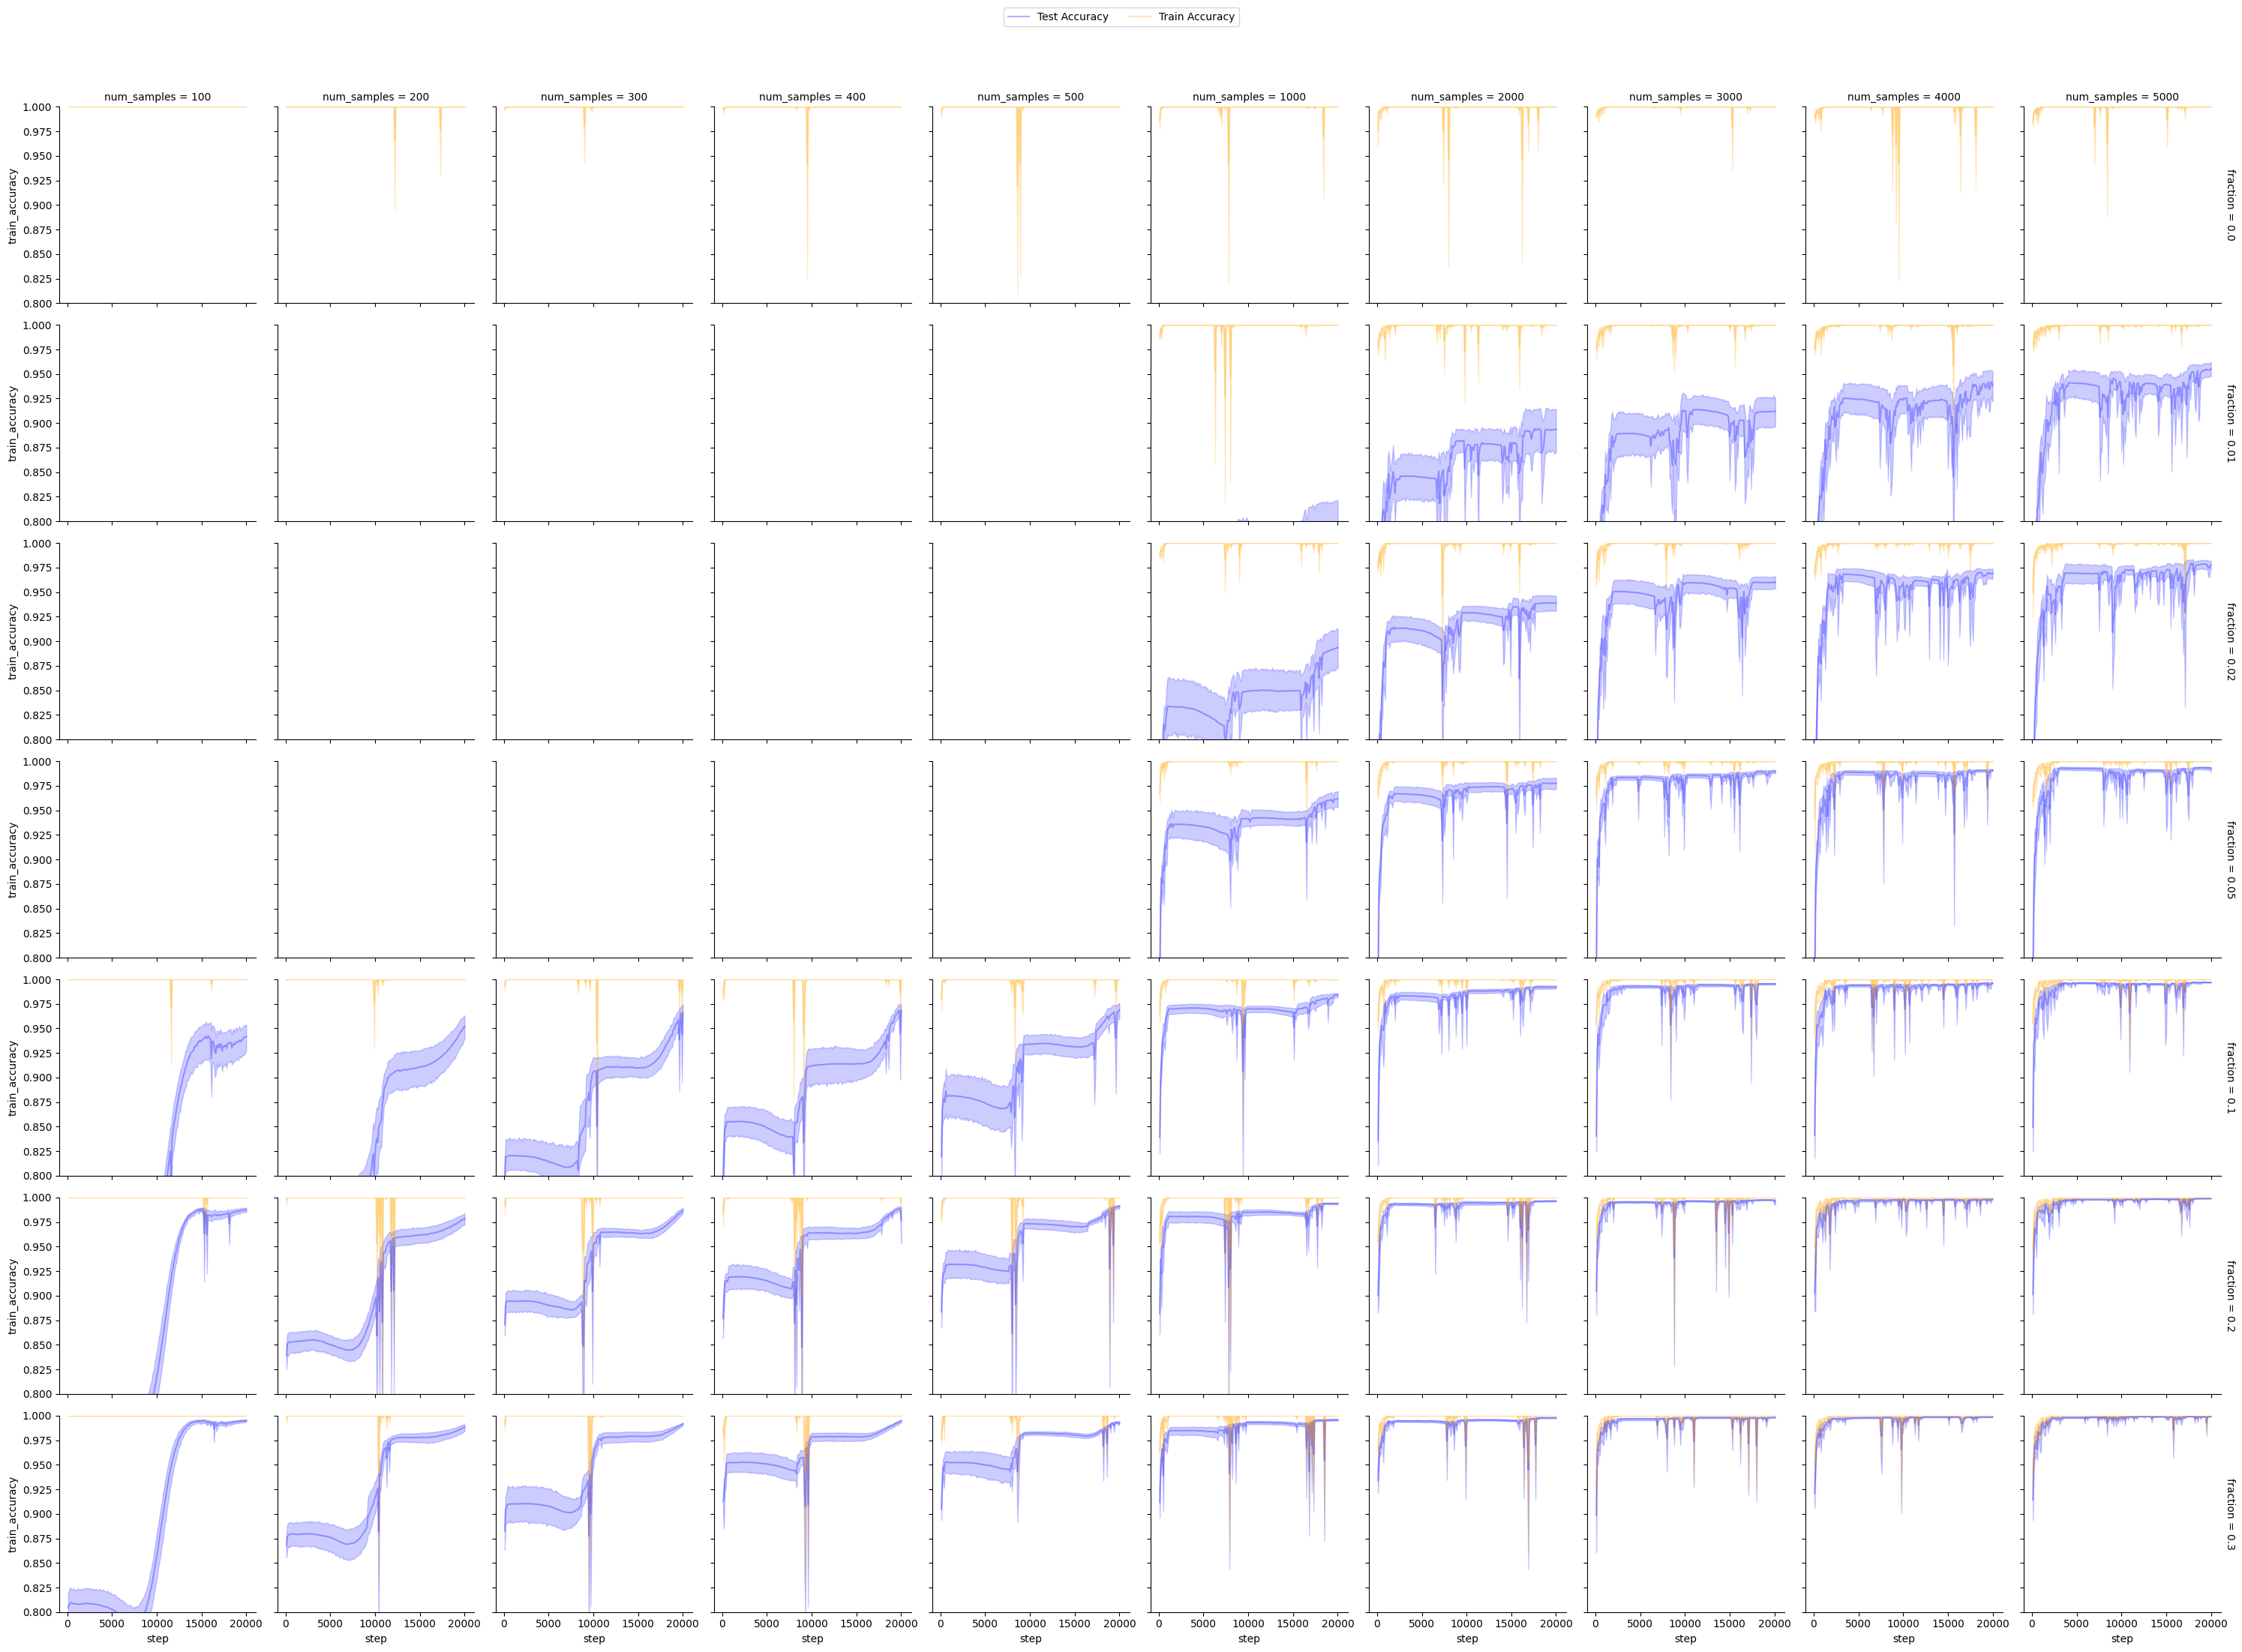

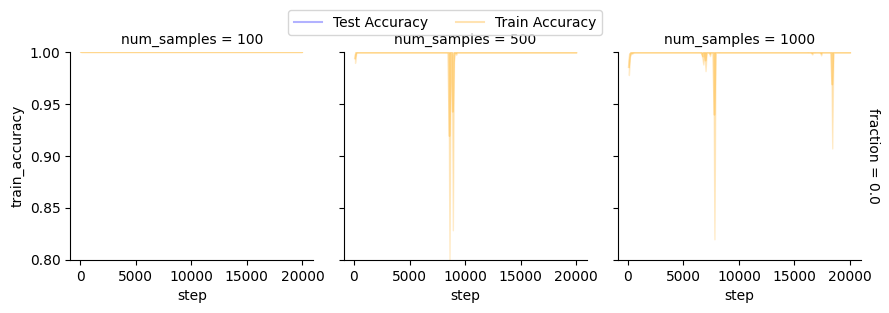

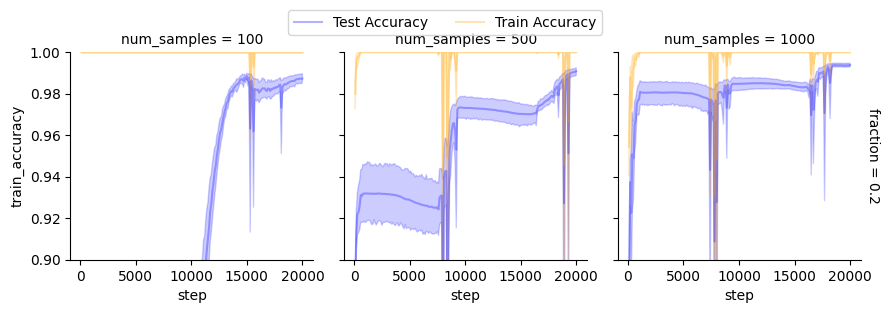

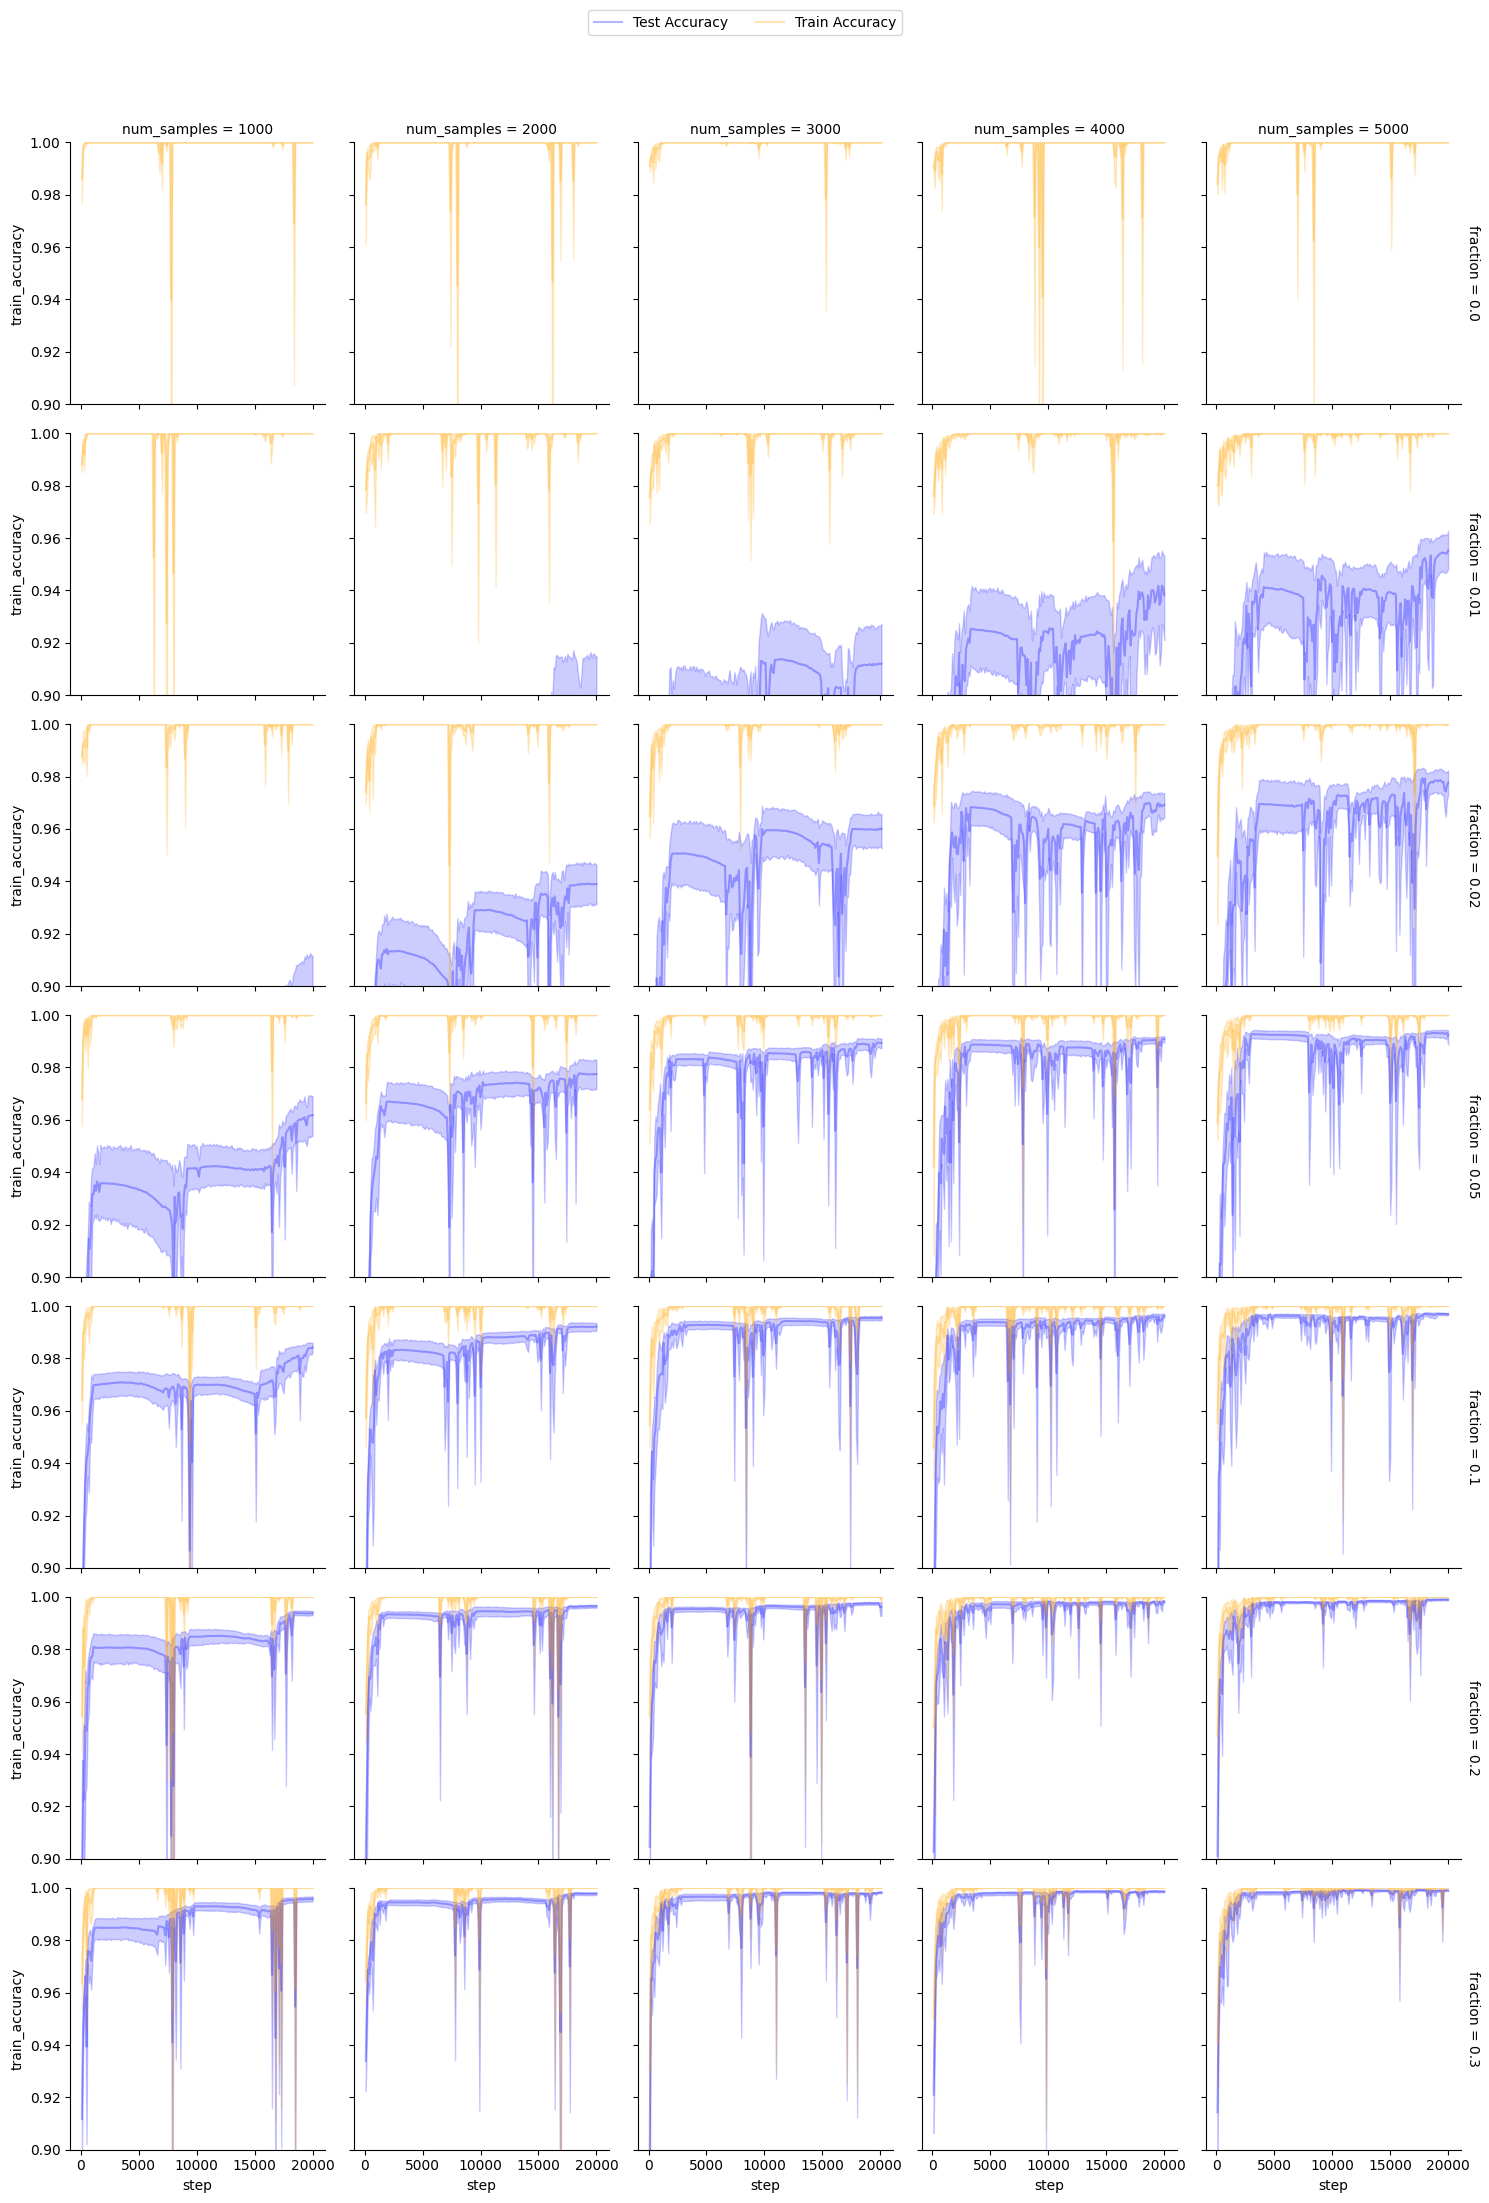

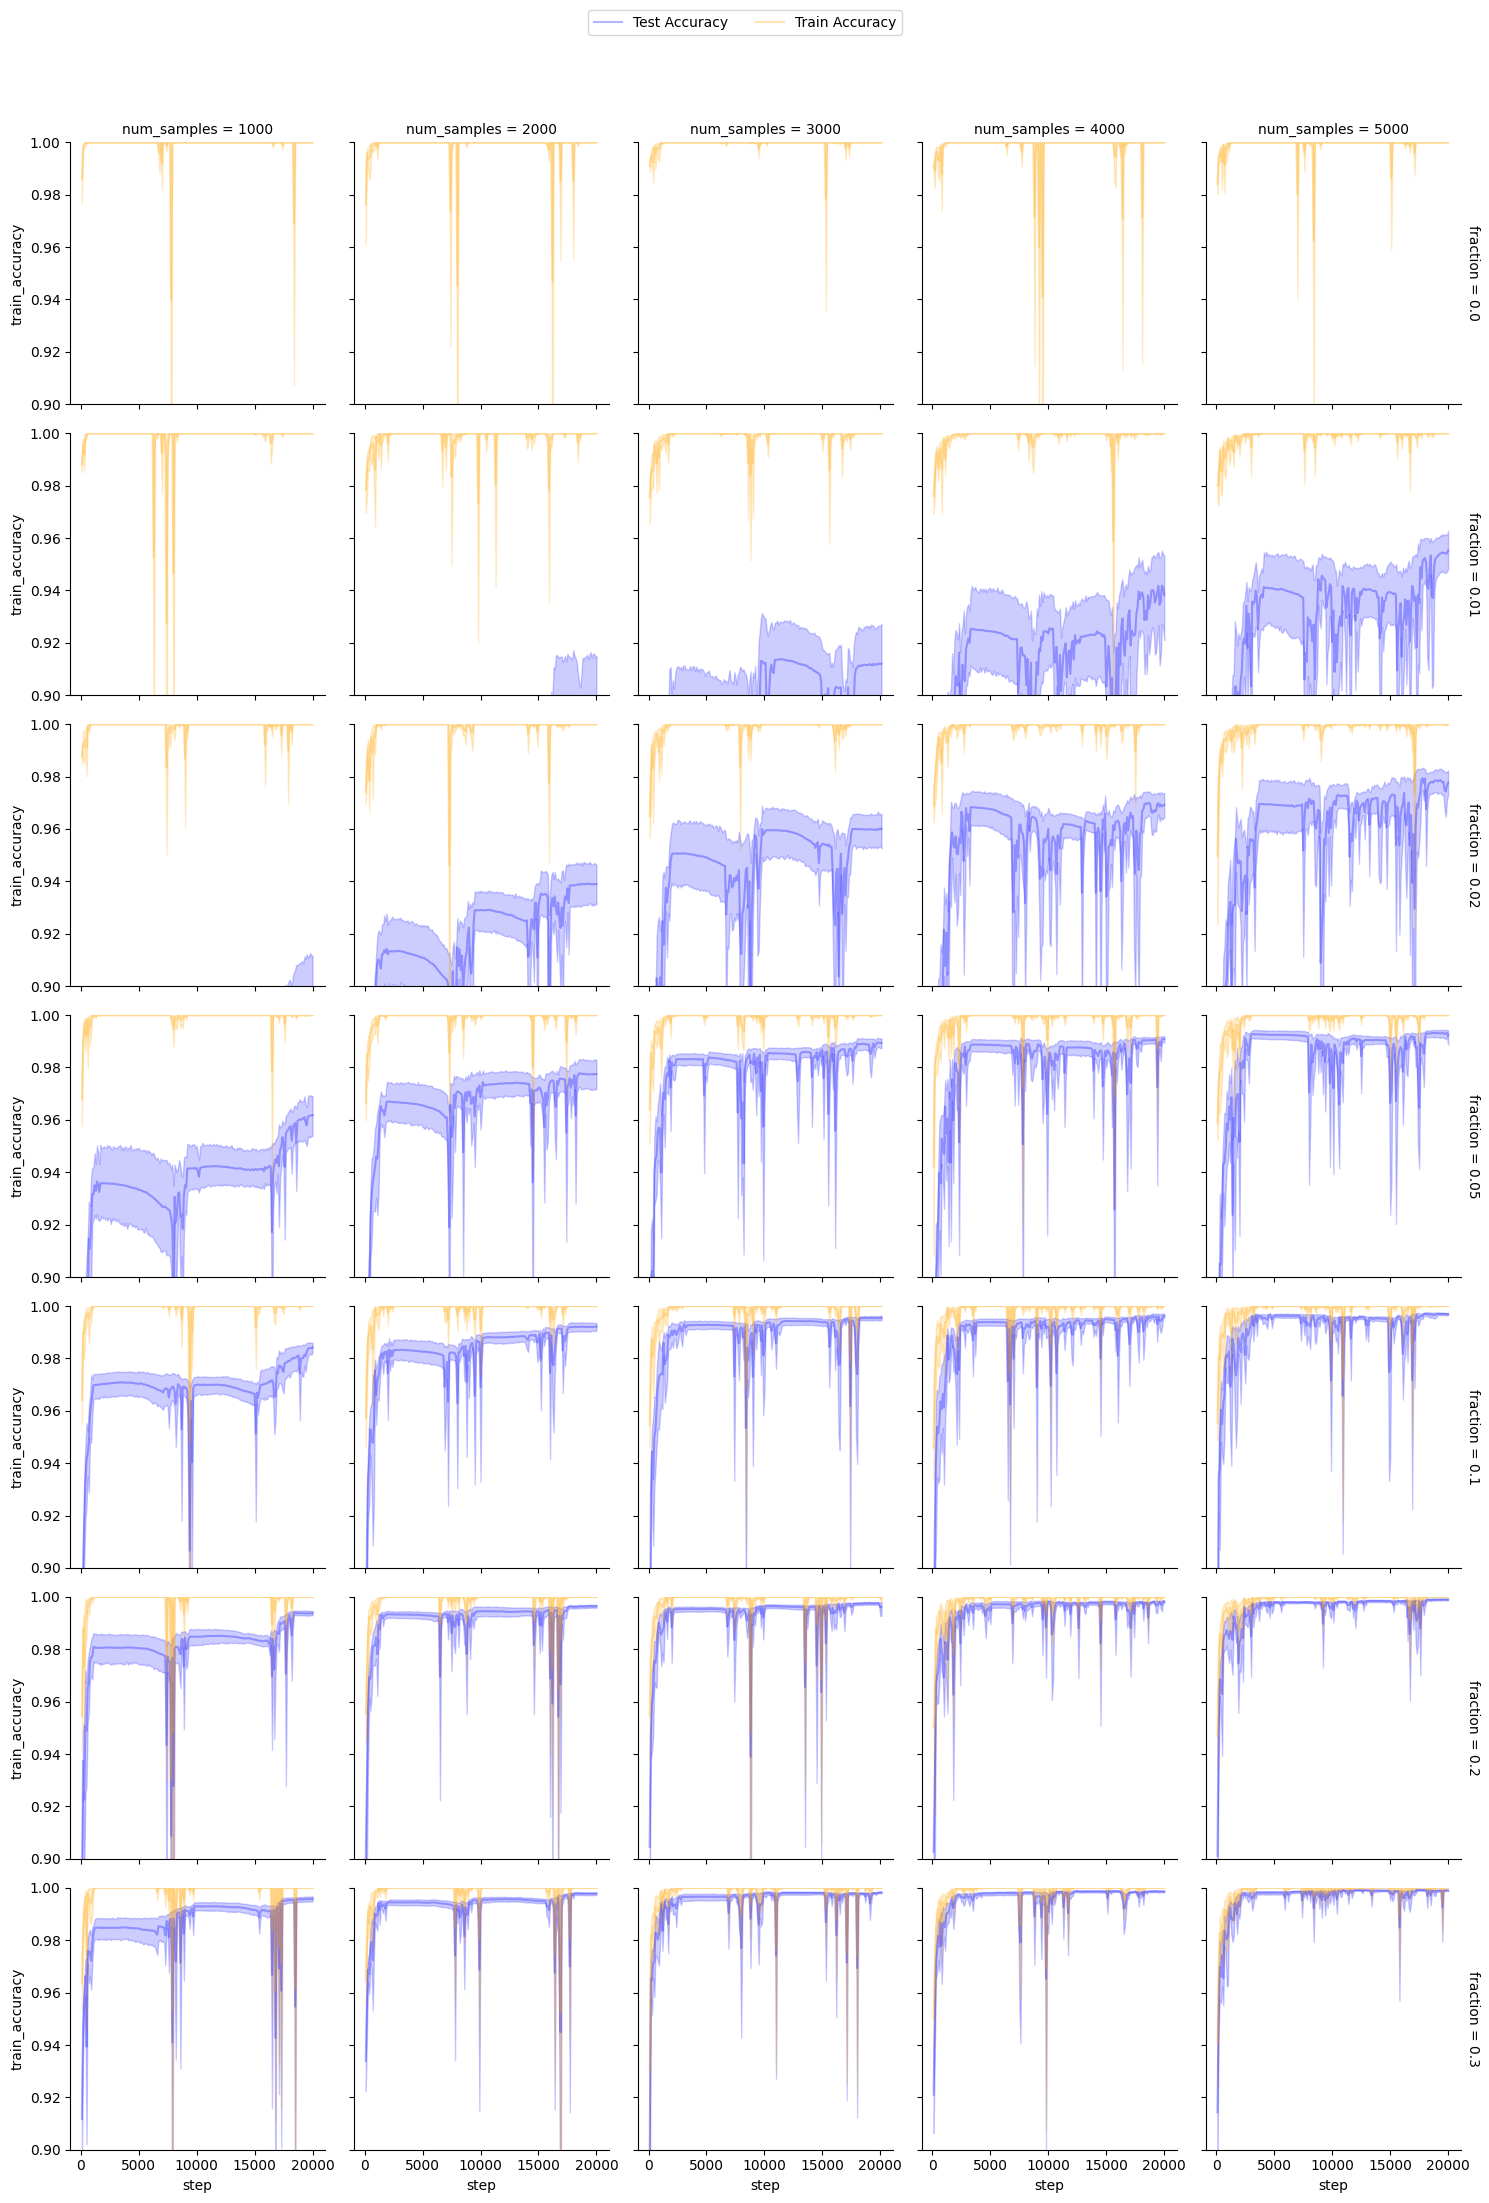

In [7]:
folder_ev = './experiments/exp_synthetic_equivariant'
print(f"Processing: {folder_ev}")
df_ev_exps = get_all_csv(folder_ev, verbose=False,)
print(f"Ploting: {folder_ev}")
results = plot_accuracy(df_ev_exps, os.path.join(folder_ev, f"result_all.pdf"), yaxis = (0.8, 1.0), alpha=0.3)
plot_accuracy(df_ev_exps, os.path.join(folder_ev, f"result_frac0.pdf"), yaxis = (0.8, 1.0), num_samples_list=[100, 500, 1000], fraction_list=[0.0], alpha=0.3)
plot_accuracy(df_ev_exps, os.path.join(folder_ev, f"result_frac01.pdf"), yaxis = (0.9, 1.0), num_samples_list=[100, 500, 1000], fraction_list=[0.2], alpha=0.3)

plot_accuracy(df_ev_exps, os.path.join(folder_ev, f"result_large.pdf"), yaxis = (0.9, 1.0), num_samples_list=[1000, 2000, 3000, 4000, 5000], alpha=0.3)

Processing: ./experiments/exp_synthetic_equidistant
Ploting: ./experiments/exp_synthetic_equidistant


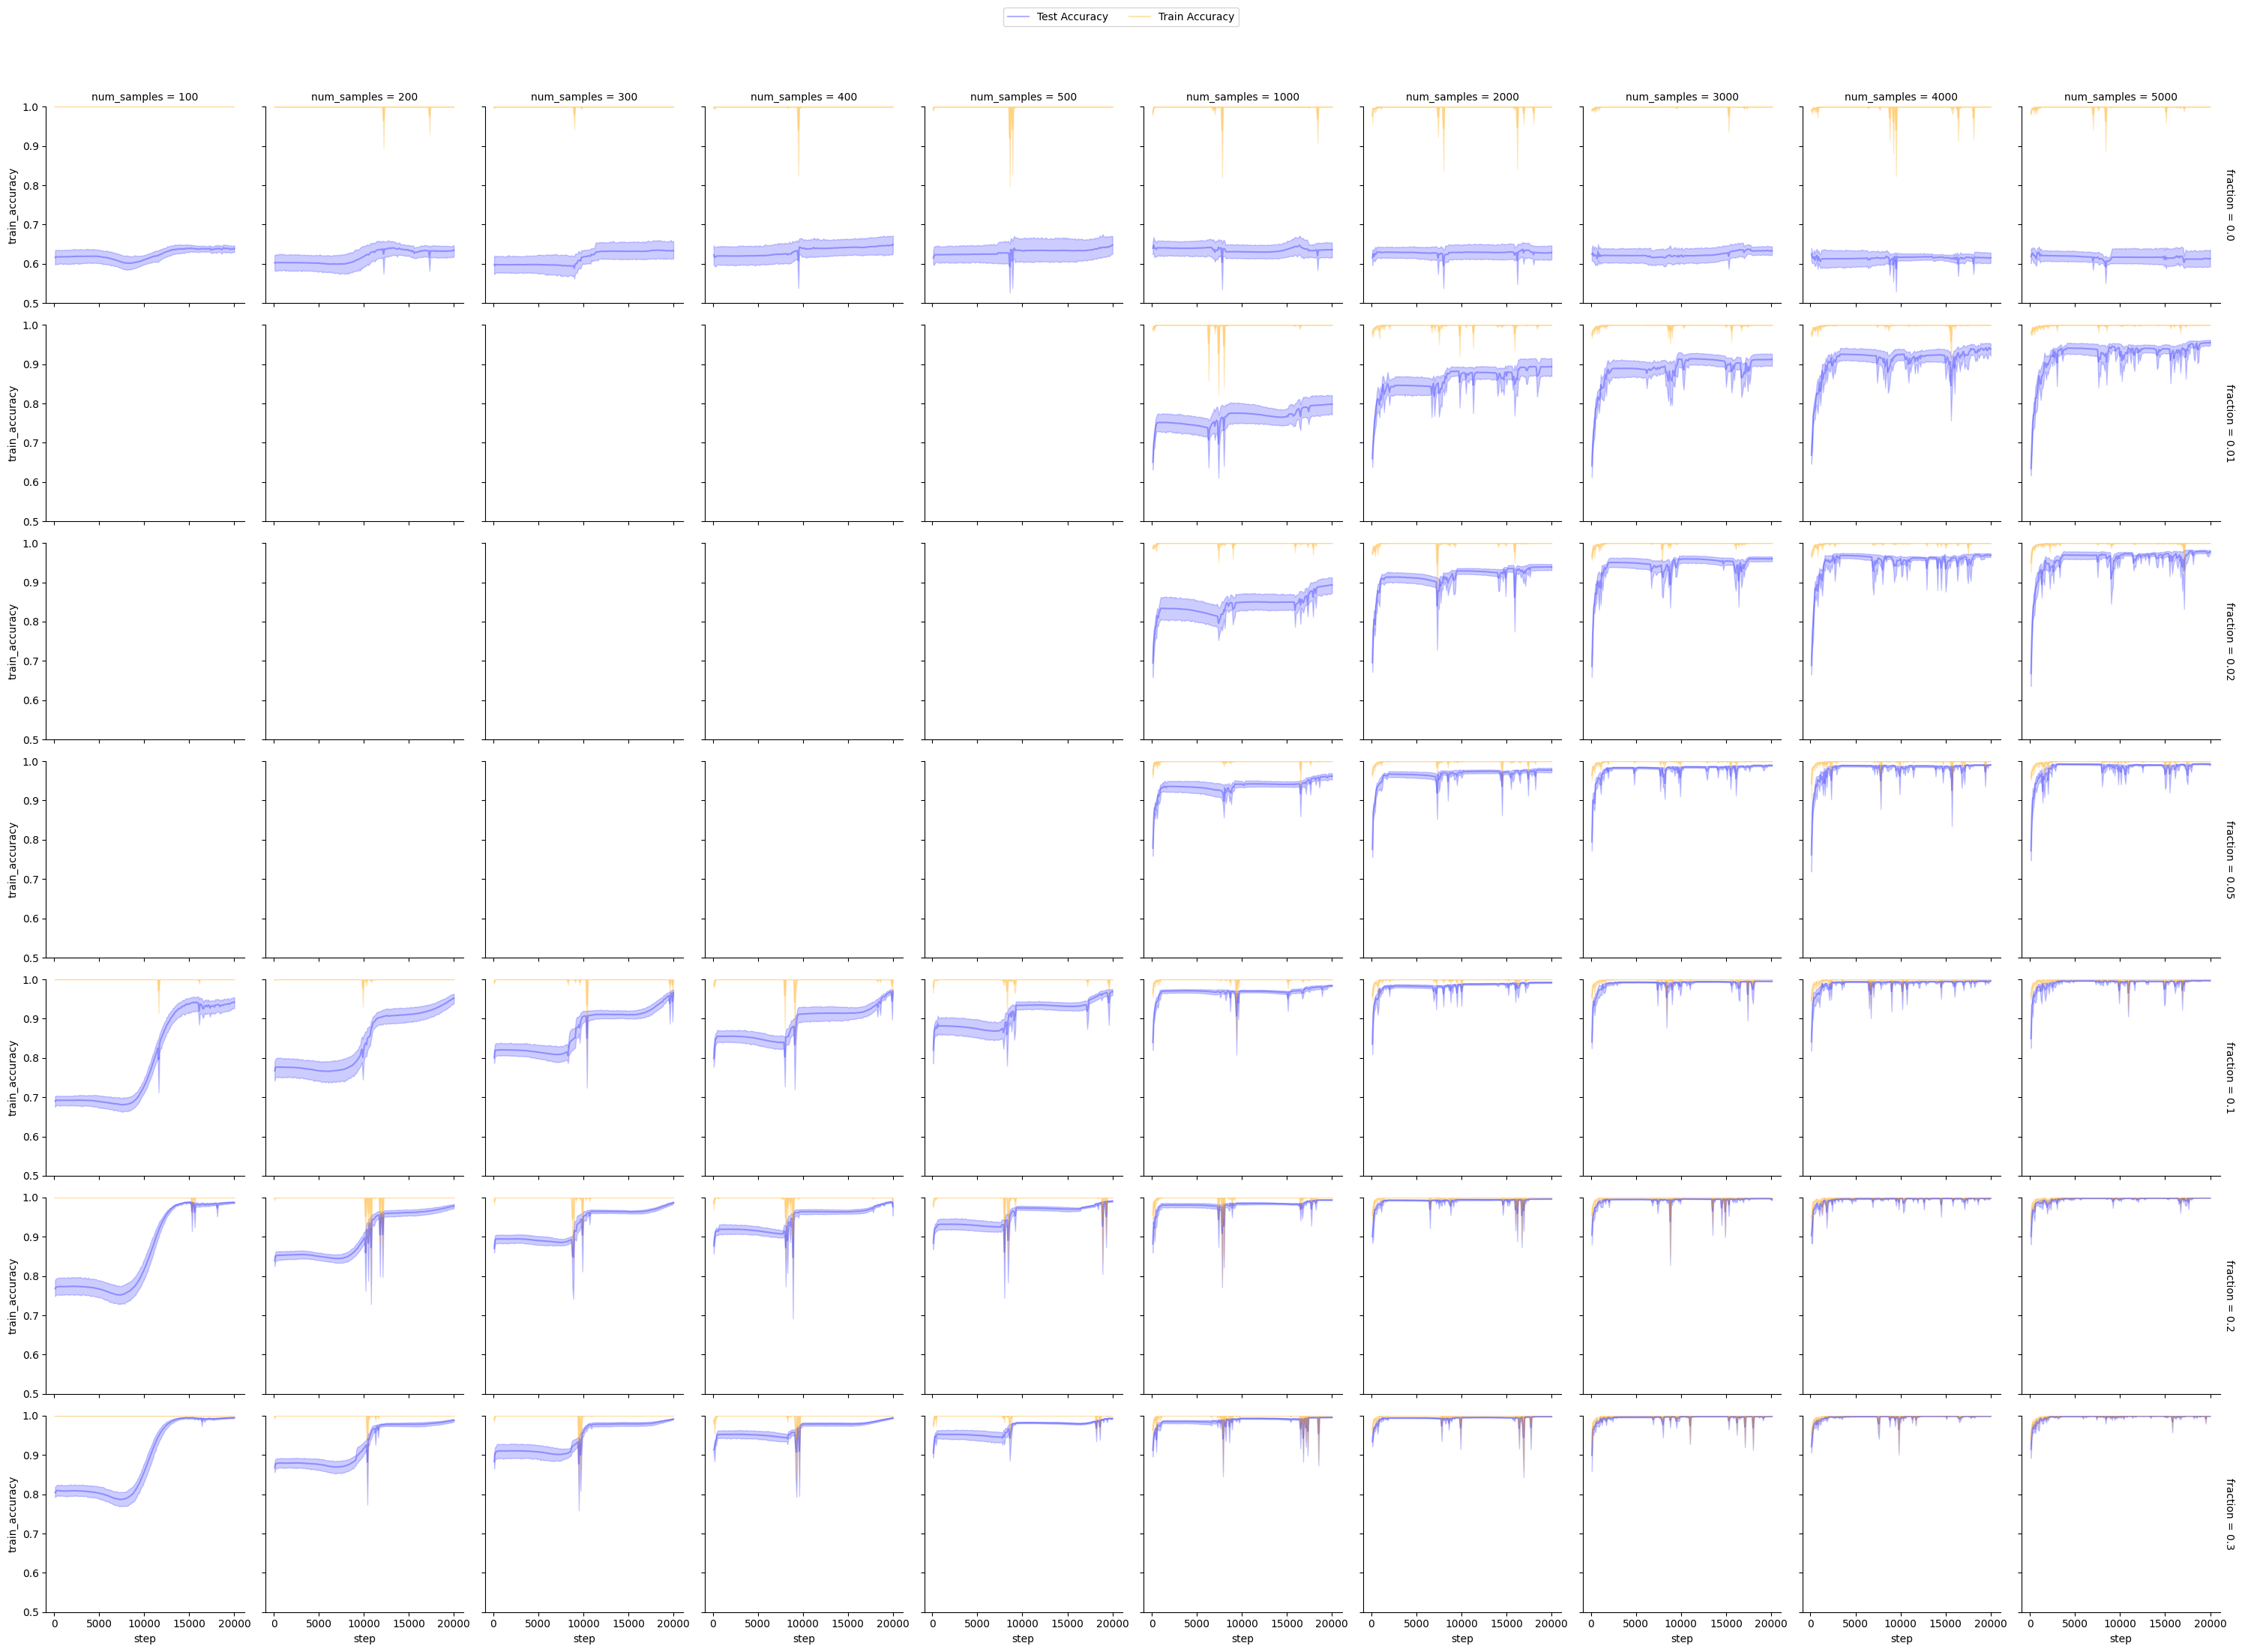

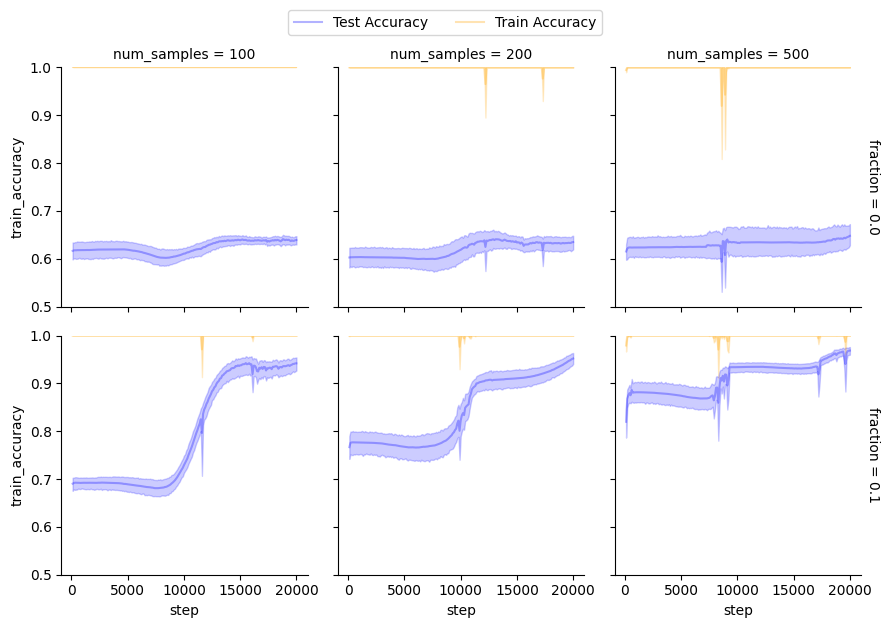

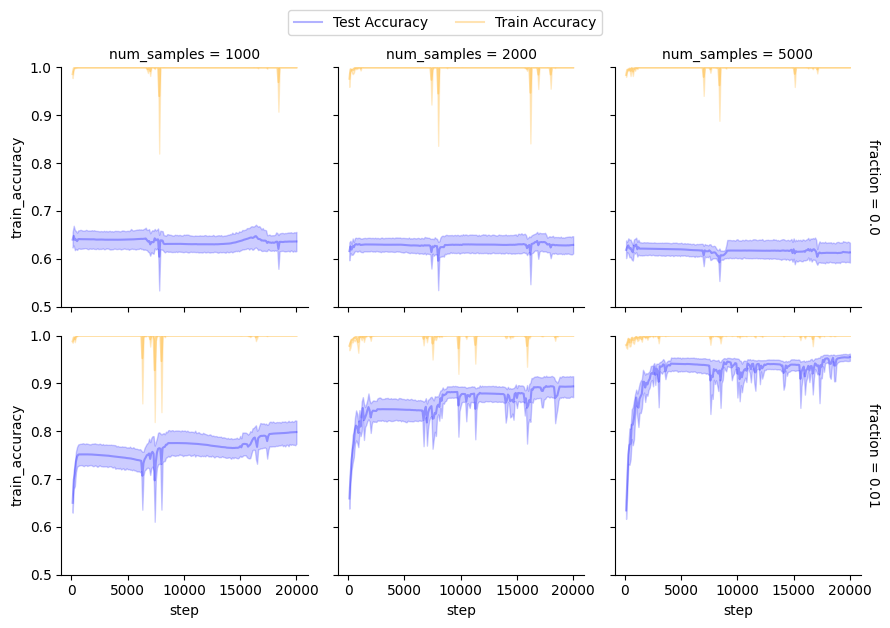

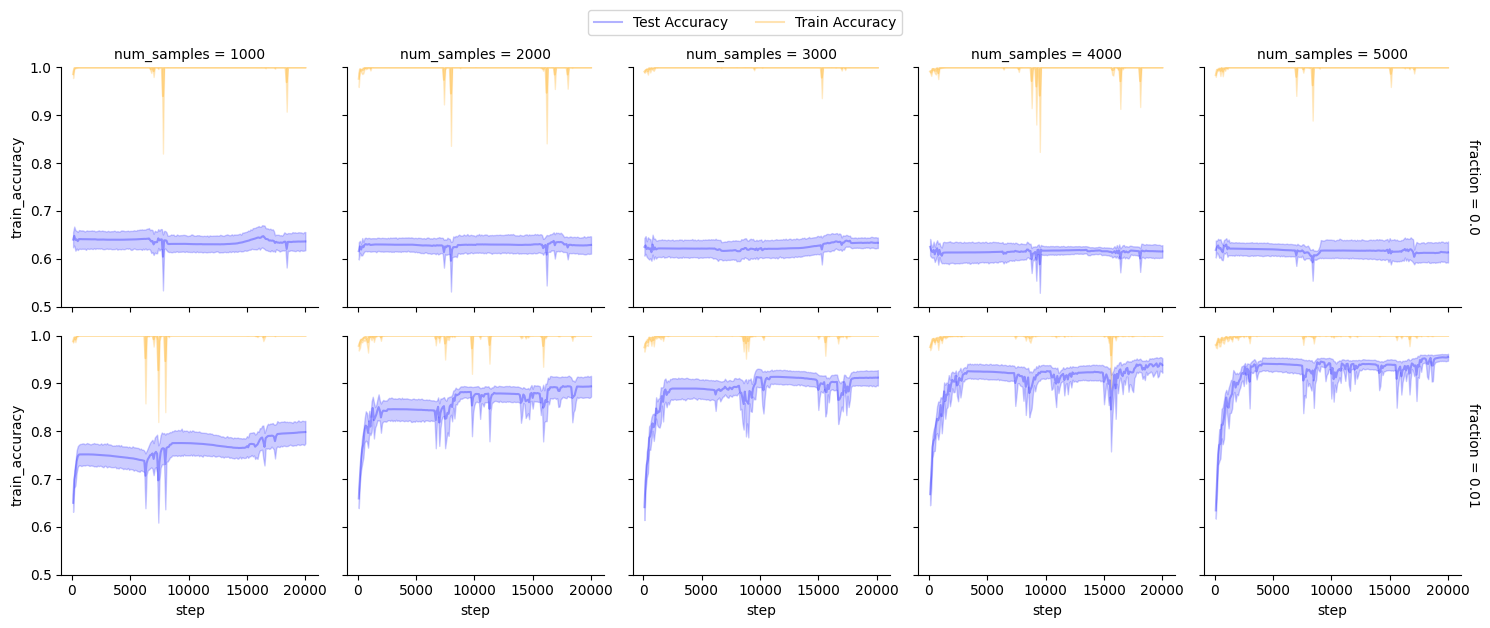

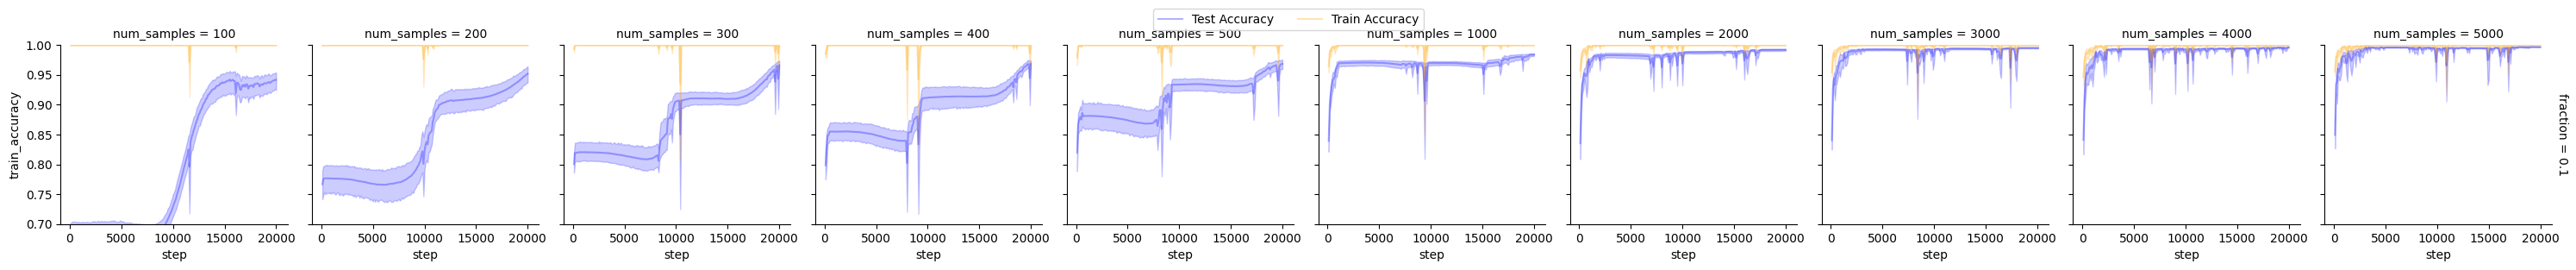

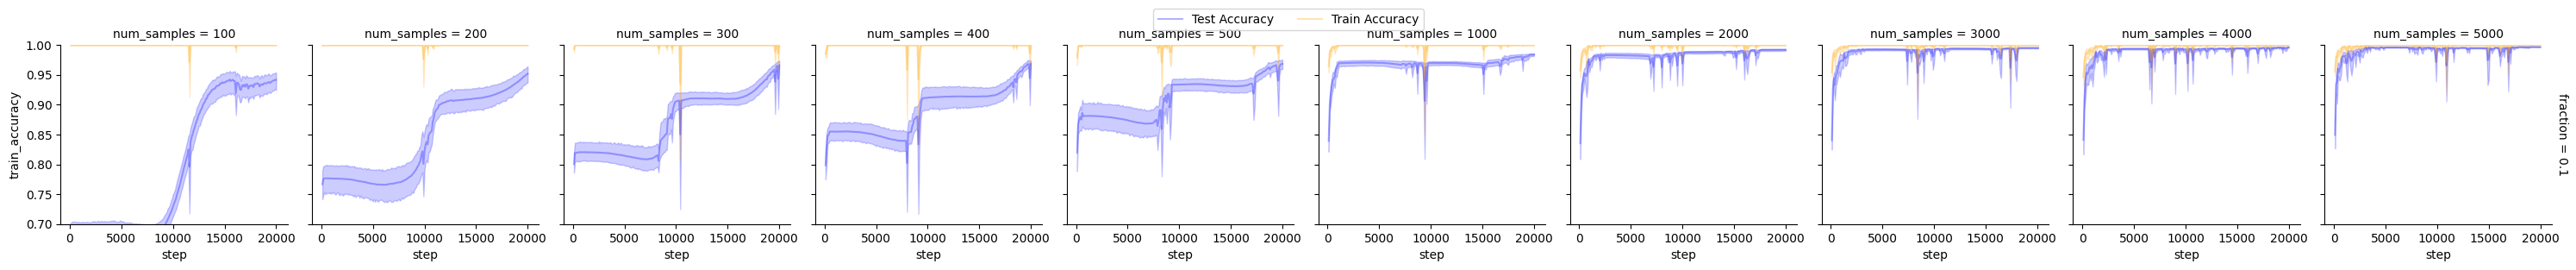

In [8]:
folder_eq = './experiments/exp_synthetic_equidistant'
print(f"Processing: {folder_eq}")
df_eq_exps = get_all_csv(folder_eq)
print(f"Ploting: {folder_eq}")
plot_accuracy(df_eq_exps, os.path.join(folder_eq, f"result_all.pdf"), alpha=0.3)
plot_accuracy(df_eq_exps, os.path.join(folder_eq, f"result_small.pdf"), num_samples_list=[100, 200, 500], fraction_list=[0.0, 0.1], alpha=0.3)
plot_accuracy(df_eq_exps, os.path.join(folder_eq, f"result_large.pdf"), num_samples_list=[1000, 2000, 5000], fraction_list=[0.0, 0.01], alpha=0.3)
plot_accuracy(df_eq_exps, os.path.join(folder_eq, f"result_large_small_frac.pdf"), num_samples_list=[1000, 2000, 3000, 4000, 5000], fraction_list=[0.0,0.01], alpha=0.3)
plot_accuracy(df_eq_exps, os.path.join(folder_eq, f"result_eq_line.pdf"), yaxis = (0.7, 1.0), fraction_list=[0.1], alpha=0.3)

In [ ]:
folder = './experiments/exps_mnist/exp_mnist_10'
print(f"Processing: {folder}")
df_exps = get_all_csv(folder, recursive=True)
print(f"Ploting: {folder}")
plot_accuracy(df_exps, os.path.join(folder, f"result_all.pdf"), alpha=0.3)
# plot_accuracy(df_exps, os.path.join(folder, f"result_small.pdf"), num_samples_list=[100, 200, 300, 400, 500], alpha=0.3)
# plot_accuracy(df_exps, os.path.join(folder, f"result_large.pdf"), num_samples_list=[1000, 2000, 3000, 4000, 5000], alpha=0.3)

Processing: exp_samples_1k-5k_frac_0.01-0.05


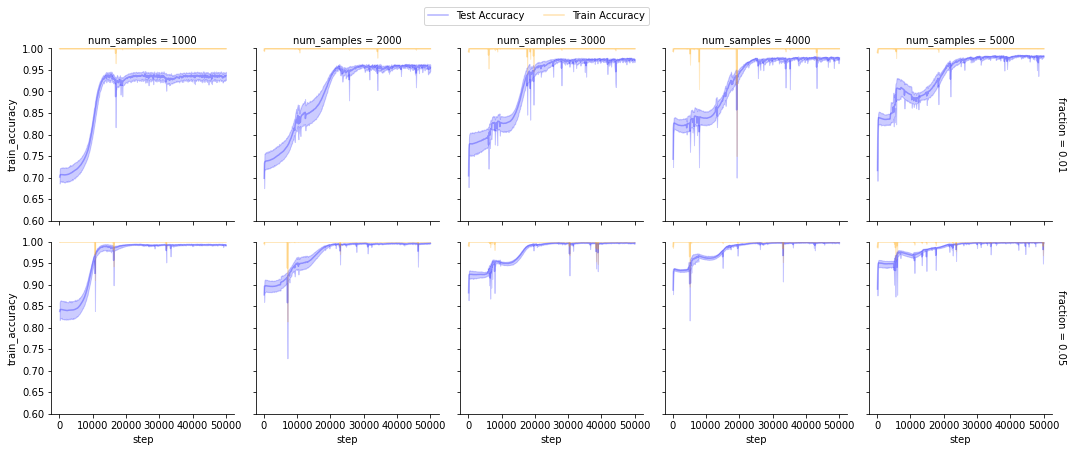

Processing: exp_samples_1k-5k_frac_0.2-1.0


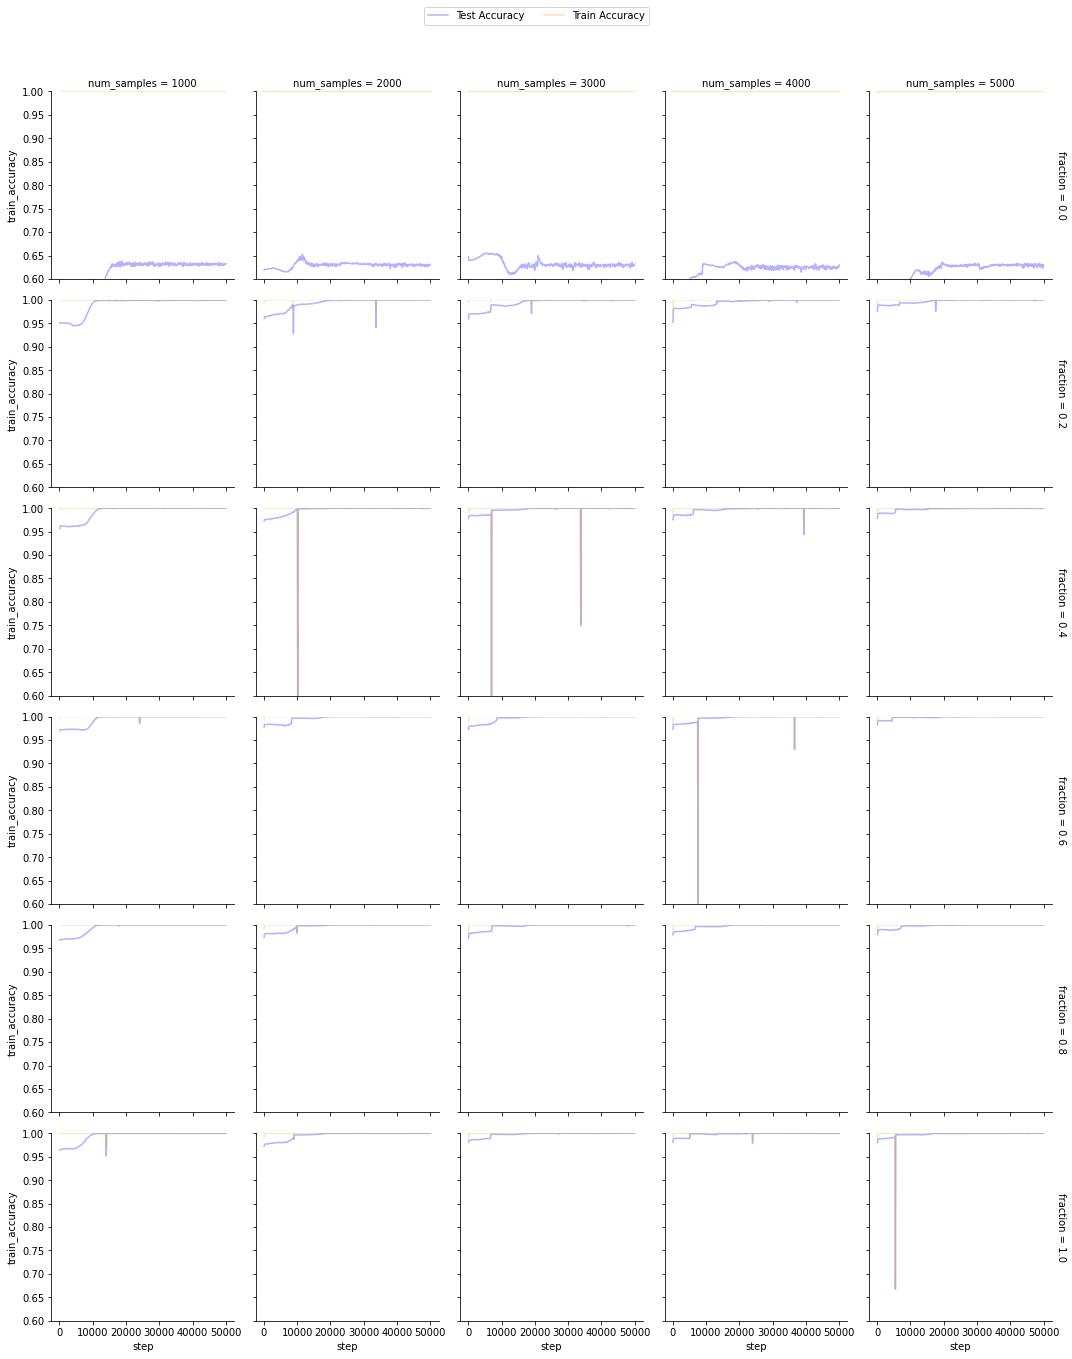

In [8]:
for folder in ['exp_samples_1k-5k_frac_0.01-0.05',
               'exp_samples_1k-5k_frac_0.2-1.0']:
    print(f"Processing: {folder}")
    df_exps = get_all_csv(folder)
    results = plot_accuracy(df_exps, os.path.join(folder, f"result_{folder}.pdf"), yaxis=(0.6, 1.0), alpha=0.3)

In [9]:
for folder in ['exp_samples_1k-5k_frac_0.01-0.05',
               'exp_samples_1k-5k_frac_0.2-1.0']:
    print(f"Processing: {folder}")
    df_exps = get_all_csv(folder)
    df_exps = df_exps[df_exps['num_samples'] == 4000 || df_exps['num_samples'] == 5000]
    results = plot_accuracy(df_exps, os.path.join(folder, f"result_{folder}_1.pdf"), yaxis=(0.8, 1.0), alpha=0.3)

SyntaxError: invalid syntax (<ipython-input-9-d664771117ce>, line 5)

Processing: exp_unb_samples_100_400_800_frac_0.0-1.0


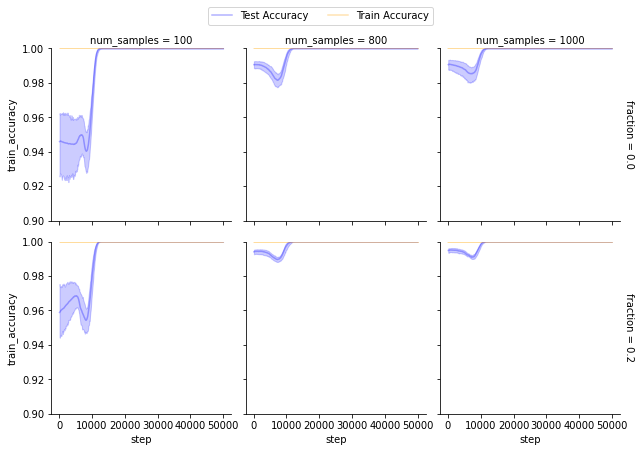

Processing: exp_unb_samples_1k-5k_frac_0.01-0.05


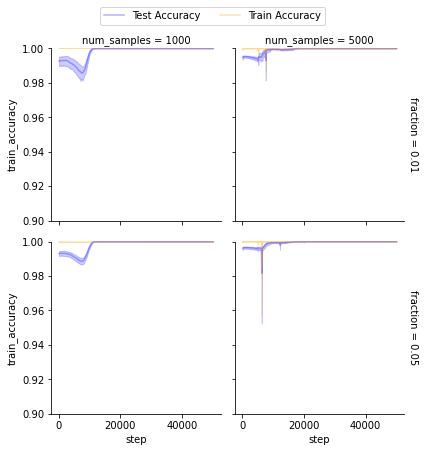

Processing: exp_unb_samples_400-800_frac_0.0-1.1


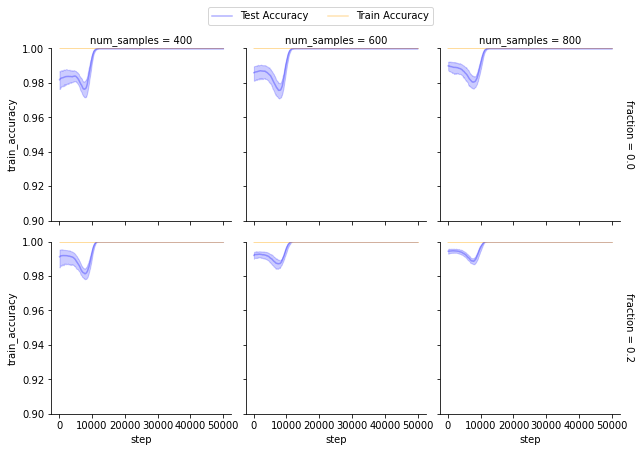

In [7]:
for folder in ['exp_unb_samples_100_400_800_frac_0.0-1.0',
               'exp_unb_samples_1k-5k_frac_0.01-0.05',
               'exp_unb_samples_400-800_frac_0.0-1.1']:
    print(f"Processing: {folder}")
    df_exps = get_all_csv(folder)
    results = plot_accuracy(df_exps, os.path.join(folder, f"result_{folder}.pdf"), yaxis=(0.9, 1.0), alpha=0.3)

Processing: exp_samples_100-200_frac_0.0-0.2-1.0_1


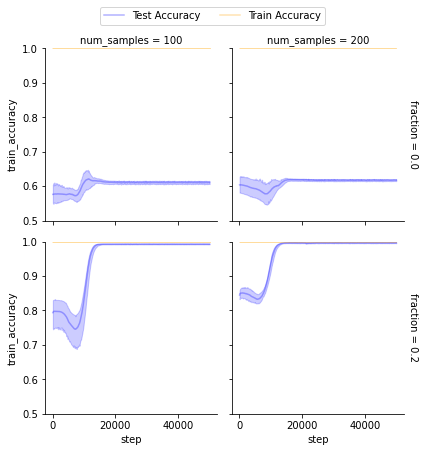

In [9]:
df_dict = dict()
for folder in ['exp_samples_100-200_frac_0.0-0.2-1.0_1']:
    print(f"Processing: {folder}")
    df_exps = get_all_csv(folder)
    df_exps = df_exps[(df_exps['fraction'] == 0.0) | (df_exps['fraction'] == 0.2)]
    results = plot_accuracy(df_exps, os.path.join(folder, f"result_{folder}_cut.pdf"), alpha=0.3)
    df_dict[folder] = df_exps, results